# Л.Р. №1. Поэлементные преобразования изображений

Выполняются три преобразования: пороговая обработка, линейное контрастирование
и эквализация гистограммы. Каждое реализовано таблично: значение пикселя
используется как номер строки таблицы преобразования

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from PIL import Image
import cv2

## Исходное изображение

Загружается изображение из списка рекомендованных — `content/04_boat.tif`;
каждый пиксель — целое число 0–255 (0 — чёрный, 255 — белый)

Размер: (512, 512) тип: uint8 мин: 0 макс: 239


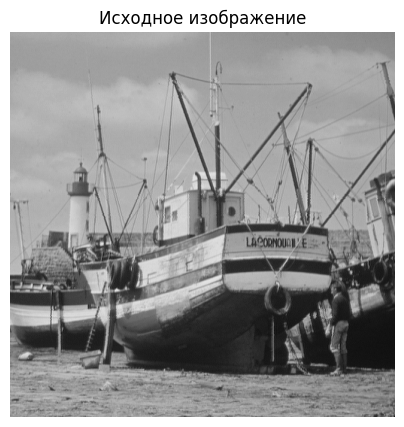

In [2]:
img = np.asarray(Image.open("./content/04_boat.tif").convert("L"))
img = np.ascontiguousarray(img).astype(np.uint8)
N = img.size
print("Размер:", img.shape, "тип:", img.dtype, "мин:", img.min(), "макс:", img.max())

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis("off")
plt.show()

## Общие функции

- `calc_hist` — гистограмма: для каждой яркости 0–255 считается число пикселей
  с такой яркостью (256 бинов на диапазоне 0–256);
- `apply_lut` — табличное поэлементное преобразование: яркость пикселя является
  номером строки таблицы `lut`, из которой берётся новое значение;
- `plot_hist`, `plot_lut` — отрисовка гистограммы и графика функции преобразования.

In [3]:
def calc_hist(a):
    hist, bins = np.histogram(a, bins=256, range=(0, 256))
    return hist, bins

def apply_lut(a, lut):
    return lut[a]

def plot_hist(ax, hist, title):
    ax.bar(np.arange(256), hist, width=1.0)
    ax.set_xlim(-1, 256)
    ax.set_title(title)
    ax.set_xlabel("яркость")
    ax.set_ylabel("число пикселей")

def plot_lut(ax, lut, title):
    ax.plot(np.arange(256), lut)
    ax.set_xlim(-1, 256)
    ax.set_ylim(0, 255)
    ax.set_title(title)
    ax.set_xlabel("вход f")
    ax.set_ylabel("выход g")
    ax.grid(True)

## I. Пороговая обработка

Пороговая обработка превращает полутоновое изображение (256 градаций) в бинарное (2 градации): пиксели с яркостью **ниже порога $t$**
становятся чёрными (0), с яркостью **$t$ и выше** — белыми (255)

In [4]:
t0 = 100

slider = widgets.IntSlider(value=t0, min=0, max=255, step=1, description="Порог")
out = widgets.Output()

def on_thr(change):
    t = int(change["new"])
    demo = np.where(img >= t, 255, 0).astype(np.uint8)
    with out:
        out.clear_output(wait=True)
        fig2, ax2 = plt.subplots(1, 2, figsize=(10, 4))
        ax2[0].imshow(demo, cmap="gray", vmin=0, vmax=255)
        ax2[0].set_title("Порог t=%d" % t)
        ax2[0].axis("off")
        ax2[1].plot(np.arange(256), np.where(np.arange(256) >= t, 255, 0))
        ax2[1].set_xlim(0, 255)
        ax2[1].set_ylim(-5, 260)
        ax2[1].set_title("LUT при t=%d" % t)
        ax2[1].grid(True)
        plt.show()

slider.observe(on_thr, names="value")
display(slider, out)
on_thr({"new": t0})

IntSlider(value=100, description='Порог', max=255)

Output()

Выбранный порог t0 = 100
белых пикселей: 76.9%, чёрных: 23.1%


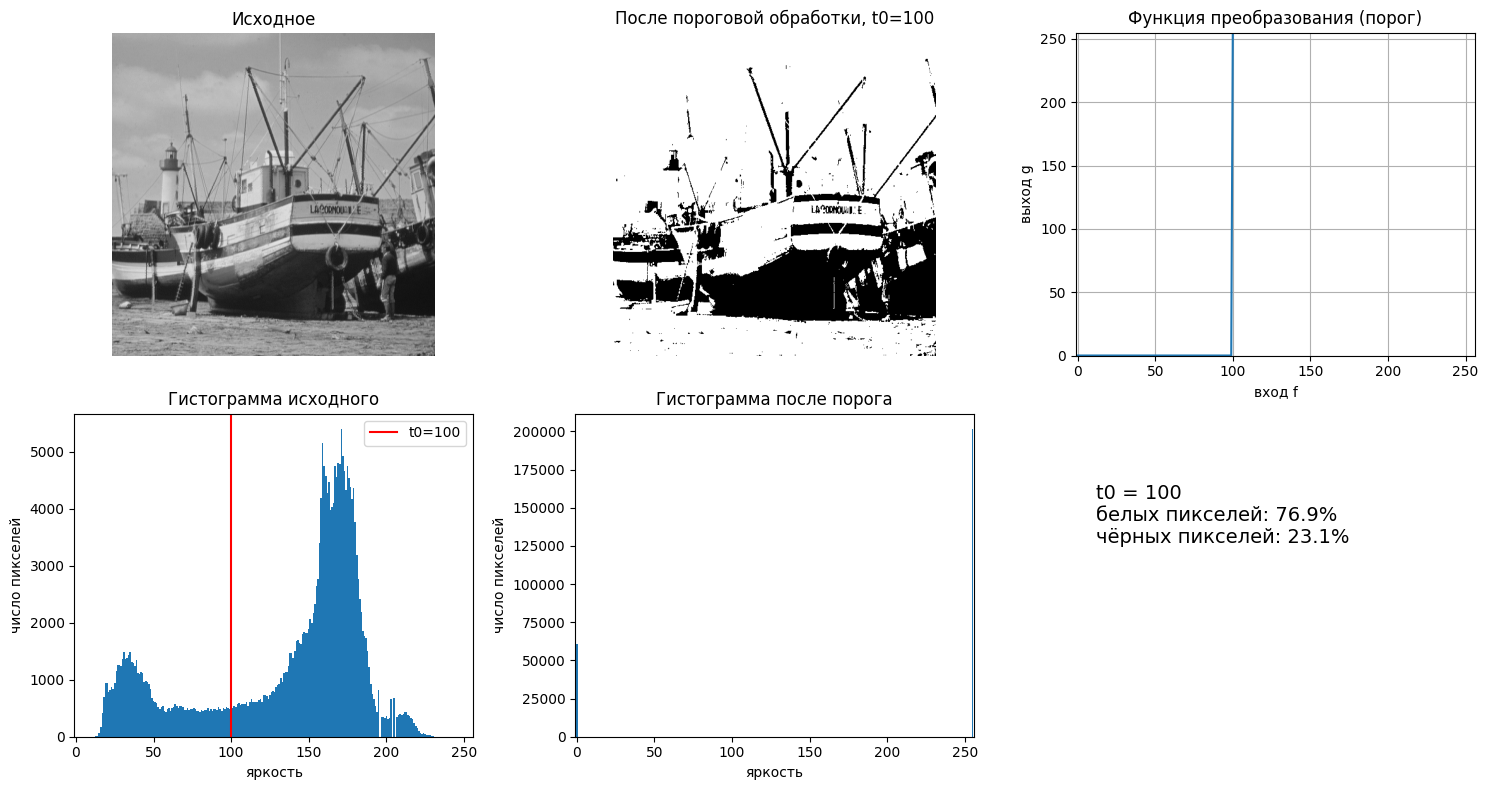

In [5]:
t0 = int(slider.value)
print("Выбранный порог t0 =", t0)

lut_thr = np.where(np.arange(256) >= t0, 255, 0).astype(np.uint8)
thr = apply_lut(img, lut_thr)
hist_thr, _ = calc_hist(thr)
hist0, _ = calc_hist(img)
print("белых пикселей: %.1f%%, чёрных: %.1f%%"
      % (100 * float(np.mean(thr == 255)), 100 * float(np.mean(thr == 0))))

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0, 0].set_title("Исходное")
ax[0, 0].axis("off")
ax[0, 1].imshow(thr, cmap="gray", vmin=0, vmax=255)
ax[0, 1].set_title("После пороговой обработки, t0=%d" % t0)
ax[0, 1].axis("off")
plot_lut(ax[0, 2], lut_thr, "Функция преобразования (порог)")
plot_hist(ax[1, 0], hist0, "Гистограмма исходного")
ax[1, 0].axvline(t0, color="r", label="t0=%d" % t0)
ax[1, 0].legend()
plot_hist(ax[1, 1], hist_thr, "Гистограмма после порога")
ax[1, 2].axis("off")
ax[1, 2].text(0.05, 0.6, "t0 = %d\nбелых пикселей: %.1f%%\nчёрных пикселей: %.1f%%"
              % (t0, 100 * float(np.mean(thr == 255)), 100 * float(np.mean(thr == 0))), fontsize=14)
fig.tight_layout()
plt.show()

**Что получилось:** Исходное полутоновое
изображение превратилось в бинарное: примерно 23% пикселей (темнее порога —
в основном фон) стали чёрными, остальные ~77% — белыми. Объекты сцены читаются
по силуэту, но все внутренние перепады яркости исчезли — это плата за сокращение
информации с 256 градаций до двух.

На гистограмме после обработки остались ровно два столбца: у 0 и у 255 —
промежуточных яркостей больше нет. На графике функции преобразования видно ту
же «ступеньку»: до порога все значения уходят в 0, начиная с порога — в 255.

## II. Линейное контрастирование

Контрастирование «растягивает» фактически используемый
диапазон яркостей $[f_{min}, f_{max}]$ на всю шкалу $[0, 255]$ при помощи
линейного преобразования $g = af + b$ с параметрами (формула (2) методички):
$a = 255/(f_{max}-f_{min})$, $b = -a\,f_{min}$.

Преобразование тождественно ($g = f$) только при
$a = 1, b = 0$, то есть когда изображение занимает весь диапазон $[0, 255]$.
Если $f_{max} < 255$, то $a > 1$ — формально не тождество, но при $a$ близком
к 1 растяжение слабое и результат почти не отличается от исходного.

Заметный эффект даёт вариант из методички
(п. 1.2, рис. 2в): в качестве $f_{min}, f_{max}$ берутся перцентили 2% / 98%,
а редкие выбросы срезаются в 0 / 255.

По min/max: fmin=0, fmax=239 -> a=1.0669, b=-0.0
Доверительные границы (рис. 2в методички): fmin'=23, fmax'=205 -> a'=1.4011, b'=-32.2
После контрастирования: строгое мин/макс = 0..255, по 2%/98% = 0..255


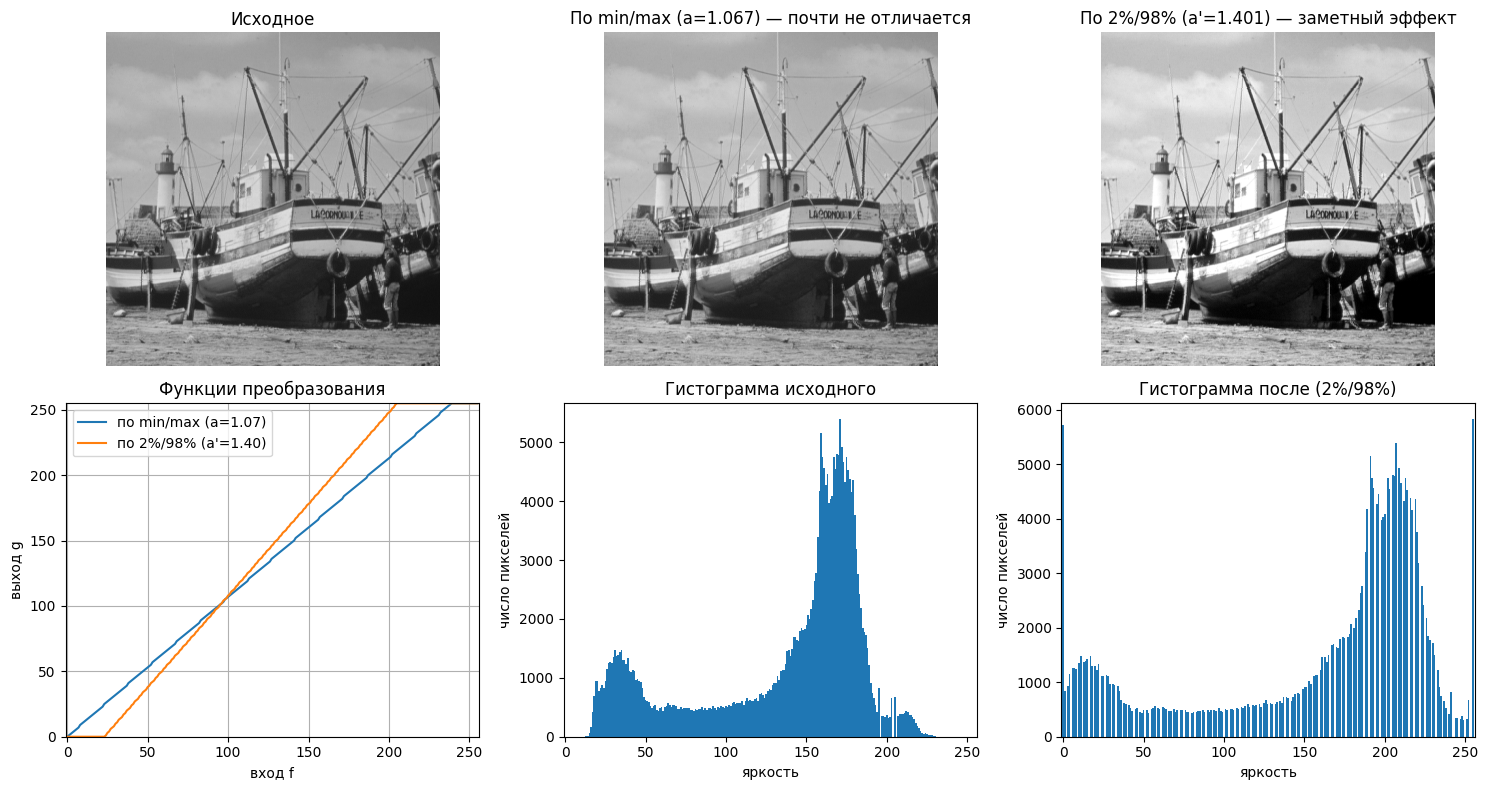

In [6]:
fmin, fmax = int(img.min()), int(img.max())
a = 255.0 / (fmax - fmin)
b = -a * fmin
print("По min/max: fmin=%d, fmax=%d -> a=%.4f, b=%.1f" % (fmin, fmax, a, b))

fmin_r = int(np.percentile(img, 2))
fmax_r = int(np.percentile(img, 98))
a_r = 255.0 / (fmax_r - fmin_r)
b_r = -a_r * fmin_r
print("Доверительные границы (рис. 2в методички): fmin'=%d, fmax'=%d -> a'=%.4f, b'=%.1f" % (fmin_r, fmax_r, a_r, b_r))

lut_strict = np.clip(np.rint(a * (np.arange(256) - fmin)), 0, 255).astype(np.uint8)
lut_con = np.clip(np.rint(a_r * (np.arange(256) - fmin_r)), 0, 255).astype(np.uint8)
con_strict = apply_lut(img, lut_strict)
con = apply_lut(img, lut_con)
hist_con, _ = calc_hist(con)
print("После контрастирования: строгое мин/макс = %d..%d, по 2%%/98%% = %d..%d"
      % (con_strict.min(), con_strict.max(), con.min(), con.max()))

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0, 0].set_title("Исходное")
ax[0, 0].axis("off")
ax[0, 1].imshow(con_strict, cmap="gray", vmin=0, vmax=255)
ax[0, 1].set_title("По min/max (a=%.3f) — почти не отличается" % a)
ax[0, 1].axis("off")
ax[0, 2].imshow(con, cmap="gray", vmin=0, vmax=255)
ax[0, 2].set_title("По 2%%/98%% (a'=%.3f) — заметный эффект" % a_r)
ax[0, 2].axis("off")
ax[1, 0].plot(np.arange(256), lut_strict, label="по min/max (a=%.2f)" % a)
ax[1, 0].plot(np.arange(256), lut_con, label="по 2%%/98%% (a'=%.2f)" % a_r)
ax[1, 0].set_xlim(-1, 256)
ax[1, 0].set_ylim(0, 255)
ax[1, 0].set_title("Функции преобразования")
ax[1, 0].set_xlabel("вход f")
ax[1, 0].set_ylabel("выход g")
ax[1, 0].legend()
ax[1, 0].grid(True)
plot_hist(ax[1, 1], hist0, "Гистограмма исходного")
plot_hist(ax[1, 2], hist_con, "Гистограмма после (2%/98%)")
fig.tight_layout()
plt.show()

- **По min/max** ($a \approx 1{,}07$): картинка практически не изменилась.
  Причина — фактический диапазон $[0, 239]$ уже почти вся шкала, растягивать
  почти нечего. Это подтверждает расчёт: тождество было бы только при полном
  диапазоне 0–255, а здесь $f_{max} = 239 < 255$.
- **По 2%/98%** ($a' \approx 1{,}40$): изображение заметно контрастнее —
  тени стали глубже, светлые участки ярче, сцена «звонче».

На гистограмме после обработки (по 2%/98%) весь диапазон 0–255 заполнен, у
краёв появились высокие столбцы — это срезанные редкие выбросы, принявшие
значения 0 и 255. Между столбцами видны пустые бины — след растяжения с
округлением: соседние входные уровни слились или разошлись.

## III. Эквализация гистограммы

Эквализация — приведение гистограммы к равномерной: все
яркости должны встречаться одинаково часто. Функция преобразования (методичка,
п. 1.3): $g = 255\,F(f)$, где $F(f)$ — интегральная (накопленная) функция
распределения яркости. Она строится через `np.cumsum` по гистограмме: в каждой
точке — суммарная доля пикселей, не яроче данной. Стандартная
`cv2.equalizeHist` используется только для сравнения.

Доля совпадающих пикселей самописной и cv2: 0.9981


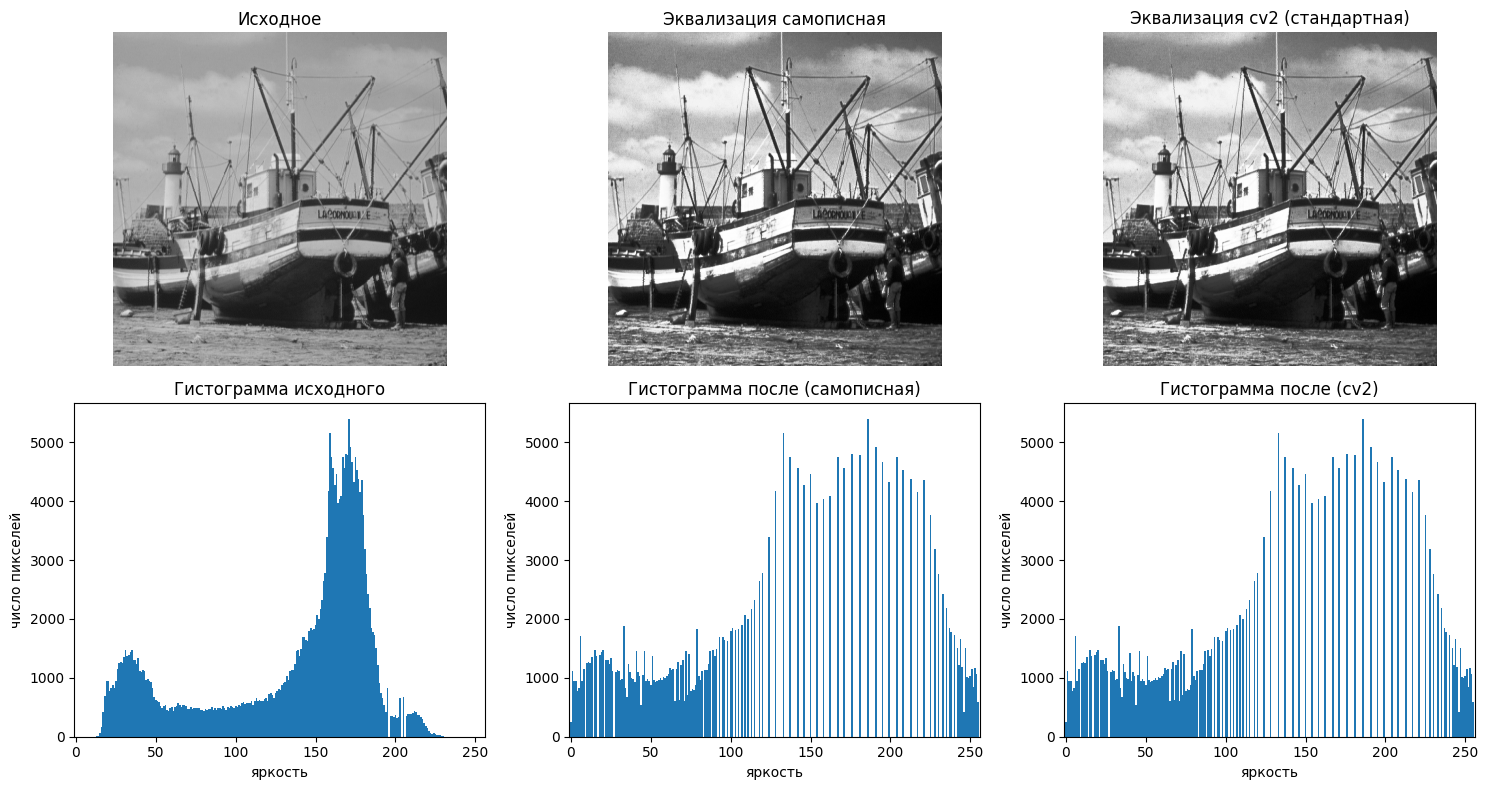

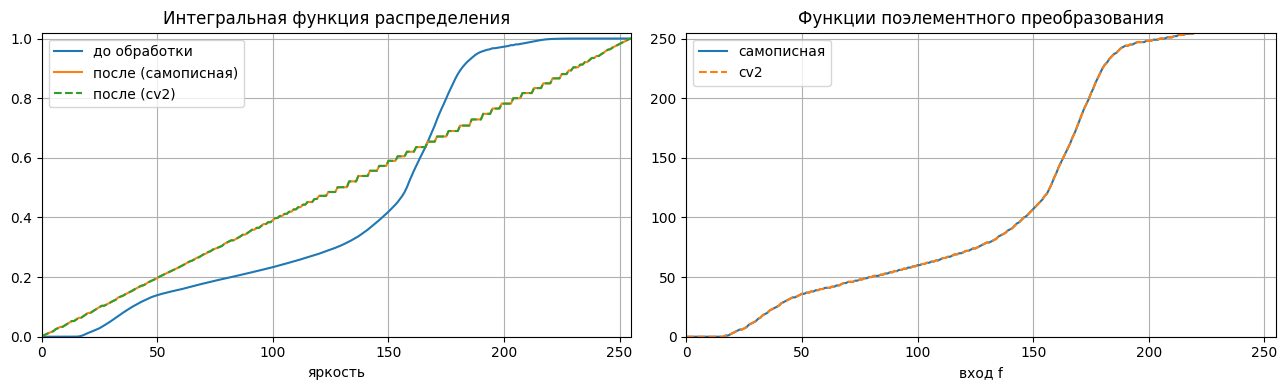

In [7]:
hist_e, bins_e = calc_hist(img)
cdf0 = np.cumsum(hist_e) / N                     # интегральная функция распределения
lut_eq = np.rint(255.0 * cdf0).astype(np.uint8)  # таблица g = 255 * F(f)
eq = apply_lut(img, lut_eq)

eq_cv = cv2.equalizeHist(img)                    # стандартная — для сравнения
print("Доля совпадающих пикселей самописной и cv2: %.4f" % float(np.mean(eq == eq_cv)))

# LUT стандартной эквализации (по первому вхождению каждого уровня) — для сравнения на графике
flat = img.reshape(-1)
uniq, first = np.unique(flat, return_index=True)
lut_cv = np.zeros(256, dtype=np.uint8)
lut_cv[uniq] = eq_cv.reshape(-1)[first]

hist_eq, _ = calc_hist(eq)
hist_cv, _ = calc_hist(eq_cv)
cdf_eq = np.cumsum(hist_eq) / N
cdf_cv = np.cumsum(hist_cv) / N

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
ax[0, 0].set_title("Исходное")
ax[0, 0].axis("off")
ax[0, 1].imshow(eq, cmap="gray", vmin=0, vmax=255)
ax[0, 1].set_title("Эквализация самописная")
ax[0, 1].axis("off")
ax[0, 2].imshow(eq_cv, cmap="gray", vmin=0, vmax=255)
ax[0, 2].set_title("Эквализация cv2 (стандартная)")
ax[0, 2].axis("off")
plot_hist(ax[1, 0], hist_e, "Гистограмма исходного")
plot_hist(ax[1, 1], hist_eq, "Гистограмма после (самописная)")
plot_hist(ax[1, 2], hist_cv, "Гистограмма после (cv2)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(np.arange(256), cdf0, label="до обработки")
ax[0].plot(np.arange(256), cdf_eq, label="после (самописная)")
ax[0].plot(np.arange(256), cdf_cv, label="после (cv2)", linestyle="--")
ax[0].set_xlim(0, 255)
ax[0].set_ylim(0, 1.02)
ax[0].set_title("Интегральная функция распределения")
ax[0].set_xlabel("яркость")
ax[0].legend()
ax[0].grid(True)
ax[1].plot(np.arange(256), lut_eq, label="самописная")
ax[1].plot(uniq, lut_cv[uniq], label="cv2", linestyle="--")  # только уровни, присутствующие в изображении
ax[1].set_xlim(0, 255)
ax[1].set_ylim(0, 255)
ax[1].set_title("Функции поэлементного преобразования")
ax[1].set_xlabel("вход f")
ax[1].legend()
ax[1].grid(True)
fig.tight_layout()
plt.show()

после эквализации картинка стала заметно контрастнее исходной — яркие участки растянулись вверх, тёмные вниз, детали в средних тонах различимее.

Признаки успешной эквализации на графиках:

- гистограмма после обработки заполняет весь диапазон 0–255 заметно
  равномернее исходной (у исходной вся масса была сжата в средней трети шкалы);
- интегральная функция распределения после обработки почти линейная —
  именно это и требуется: равномерному распределению соответствует линейная
  «накопленная» кривая;
- самописная эквализация и `cv2.equalizeHist` практически совпадают: пиксели
  совпадают на ~99,8%, кривые функций преобразования наложились друг на друга.
  Это подтверждает, что формула $g = 255\,F(f)$ реализована верно.

По требованию задания ниже печатаются массивы, выданные функцией
`hist, bins = np.histogram(...)`: `hist` — число пикселей в каждом из 256
интервалов, `bins` — границы этих интервалов. Проверяется, что `bins`
начинается с нуля и содержит числа 0, 1, 2, 3, ..., 255, 256: интервалы имеют
длину 1 и примыкают друг к другу, покрывая диапазон яркостей 0–255.

In [8]:
hist, bins = np.histogram(img, bins=256, range=(0, 256))
with np.printoptions(threshold=np.inf):
    print("hist (гистограмма исходного изображения):")
    print(hist)
    print("bins (границы интервалов):")
    print(bins)
print("bins == 0..256:", bool(np.array_equal(bins, np.arange(257))))

hist (гистограмма исходного изображения):
[   1    0    0    0    0    0    0    1    0    0    1    1    2   13
    7   60  166  413  696  945  939  778  822  876  835  940 1146 1255
 1266 1248 1359 1478 1365 1383 1432 1481 1305 1297 1234 1344 1122 1106
 1131 1112  965  977  952  928  833  680  626  604  586  520  480  517
  531  447  441  491  497  444  507  525  569  533  504  539  534  515
  472  476  507  463  483  492  496  490  452  447  439  463  446  467
  465  499  451  482  455  491  491  467  519  481  447  510  493  518
  500  490  526  511  547  526  573  598  552  578  566  577  604  547
  611  666  608  617  605  608  646  659  614  725  735  711  665  734
  784  806  786  871  910  921 1029  963 1120 1131 1133 1232 1462 1466
 1372 1495 1686 1699 1642 1621 1798 1840 1817 1827 1890 2064 1996 2174
 2327 2647 2774 3394 4178 5152 4755 4567 4268 4465 3971 4034 4096 4745
 4555 4808 4782 5394 4927 4664 4322 4756 4535 4374 4163 4367 3759 3184
 2764 2423 2183 1851 1775 1724 1507